<a href="https://colab.research.google.com/github/MNMARQUES/MachineLearning/blob/main/EML__Projeto2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [8]:

# URL oficial e altamente estável do repositório de Machine Learning da UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

colunas = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

# O arquivo da UCI não possui cabeçalho, então definimos header=None
df = pd.read_csv(url, header=None, names=colunas)

print("Dataset carregado com sucesso!")
print("Dimensões:", df.shape)

df.head()

Dataset carregado com sucesso!
Dimensões: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [9]:

# Informações gerais
print("Dimensões do dataset:", df.shape)

print("\nTipos de dados:")
print(df.dtypes)

print("\nInformações gerais:")
df.info()

print("\nEstatísticas descritivas:")
display(df.describe())

print("\nValores ausentes por coluna:")
print(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nDistribuição das classes:")
print(df["class"].value_counts().sort_index())


Dimensões do dataset: (1372, 5)

Tipos de dados:
variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Estatísticas descritivas:


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000



Valores ausentes por coluna:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Registros duplicados:
24

Distribuição das classes:
class
0    762
1    610
Name: count, dtype: int64


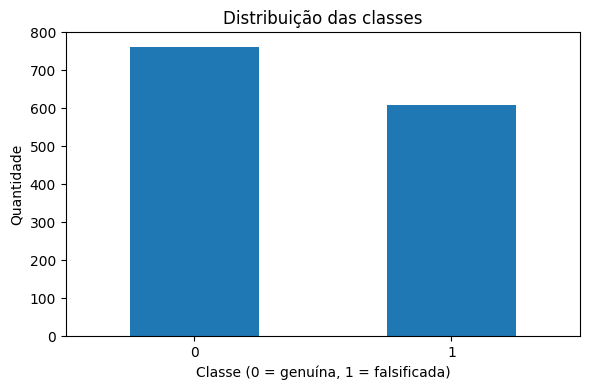

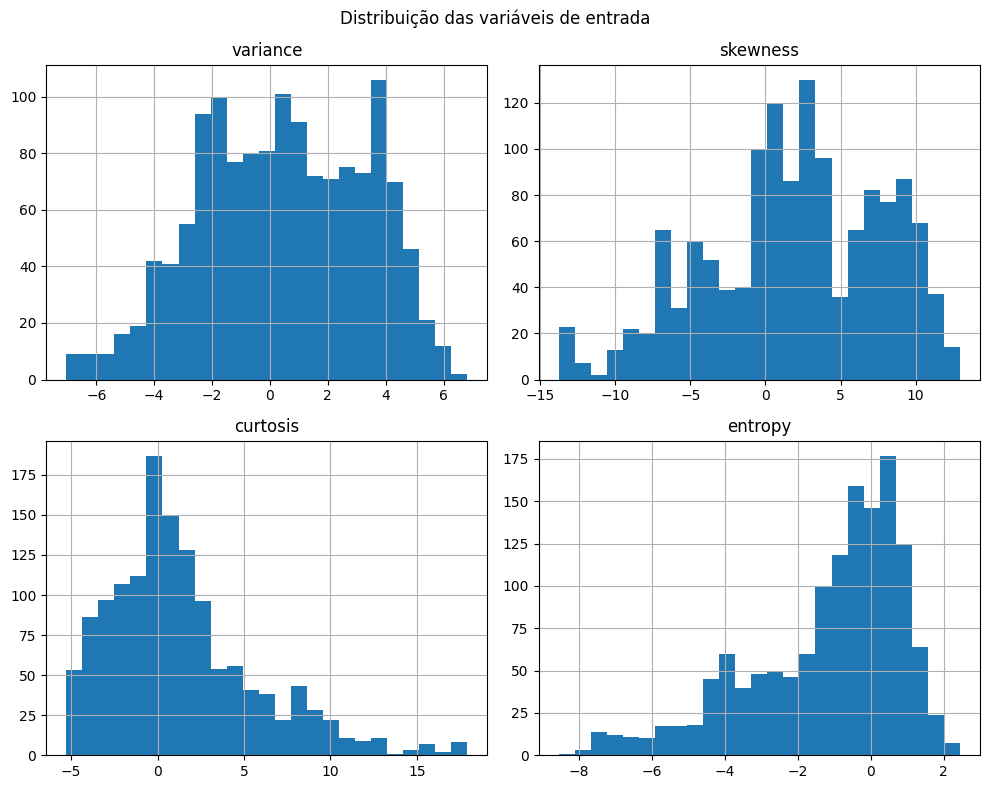

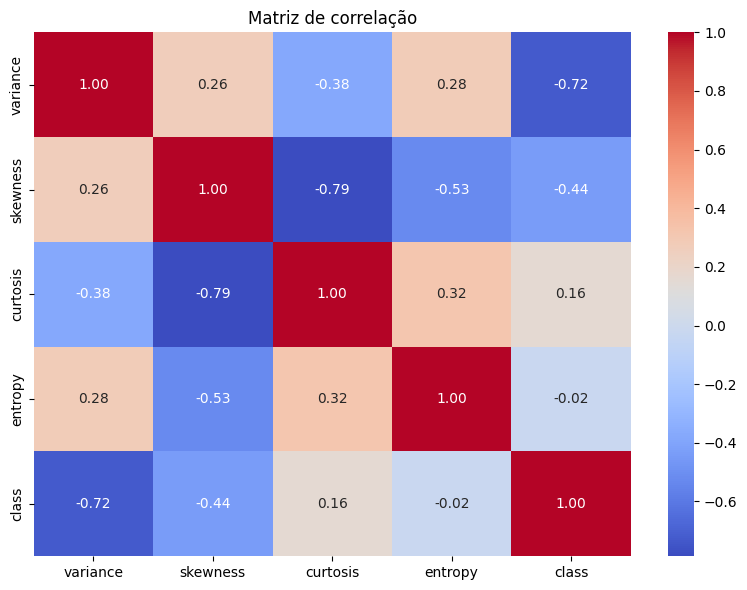

In [10]:

# Distribuição das classes
df["class"].value_counts().sort_index().plot(
    kind="bar",
    rot=0,
    figsize=(6, 4)
)

plt.title("Distribuição das classes")
plt.xlabel("Classe (0 = genuína, 1 = falsificada)")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

# Distribuição das variáveis numéricas
df.drop(columns="class").hist(
    figsize=(10, 8),
    bins=25
)

plt.suptitle("Distribuição das variáveis de entrada")
plt.tight_layout()
plt.show()

# Correlação entre as variáveis
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlação")
plt.tight_layout()
plt.show()


In [11]:

X = df.drop(columns=["class"])
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1
)

print("Amostras para treinamento:", X_train.shape[0])
print("Amostras para teste:", X_test.shape[0])

print("\nDimensões de X_train:", X_train.shape)
print("Dimensões de X_test:", X_test.shape)
print("Dimensões de y_train:", y_train.shape)
print("Dimensões de y_test:", y_test.shape)


Amostras para treinamento: 960
Amostras para teste: 412

Dimensões de X_train: (960, 4)
Dimensões de X_test: (412, 4)
Dimensões de y_train: (960,)
Dimensões de y_test: (412,)


In [12]:

clf_KNN = KNeighborsClassifier(n_neighbors=5)

clf_arvore = DecisionTreeClassifier(
    random_state=1
)

clf_floresta = RandomForestClassifier(
    max_depth=8,
    random_state=1
)

clf_svm = SVC(
    gamma="auto",
    kernel="rbf",
    random_state=1
)

clf_mlp = MLPClassifier(
    hidden_layer_sizes=(2,),
    solver="lbfgs",
    random_state=1
)

modelos = {
    "KNN": clf_KNN,
    "Árvore de Decisão": clf_arvore,
    "Random Forest": clf_floresta,
    "SVM": clf_svm,
    "MLP": clf_mlp
}

print("Cinco modelos configurados com sucesso!")


Cinco modelos configurados com sucesso!


In [13]:

resultados = []
previsoes = {}

for nome, modelo in modelos.items():
    # Treinamento
    modelo.fit(X_train, y_train)

    # Previsões sobre dados não utilizados no treino
    y_pred = modelo.predict(X_test)
    previsoes[nome] = y_pred

    # Métricas de avaliação
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

print("Treinamento e previsões concluídos!")


Treinamento e previsões concluídos!


In [14]:

df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by="Acurácia",
    ascending=False
).reset_index(drop=True)

display(
    df_resultados.style.format({
        "Acurácia": "{:.4f}",
        "Precisão": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)


,Modelo,Acurácia,Precisão,Recall,F1-score
0,MLP,1.0000,1.0000,1.0000,1.0000
1,SVM,1.0000,1.0000,1.0000,1.0000
2,KNN,0.9976,0.9944,1.0000,0.9972
3,Random Forest,0.9951,0.9888,1.0000,0.9944
4,Árvore de Decisão,0.9879,0.9778,0.9944,0.9860


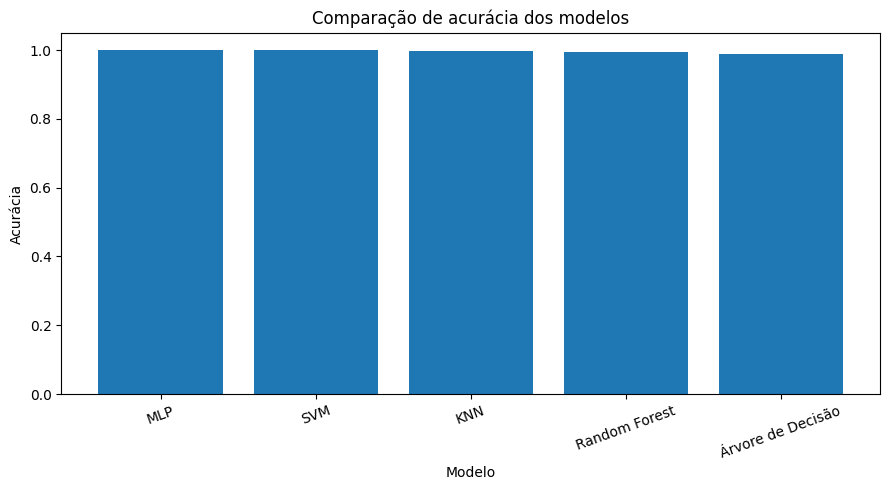

In [15]:

plt.figure(figsize=(9, 5))

plt.bar(
    df_resultados["Modelo"],
    df_resultados["Acurácia"]
)

plt.title("Comparação de acurácia dos modelos")
plt.xlabel("Modelo")
plt.ylabel("Acurácia")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


MODELO: KNN
                 precision    recall  f1-score   support

    Genuína (0)       1.00      1.00      1.00       235
Falsificada (1)       0.99      1.00      1.00       177

       accuracy                           1.00       412
      macro avg       1.00      1.00      1.00       412
   weighted avg       1.00      1.00      1.00       412



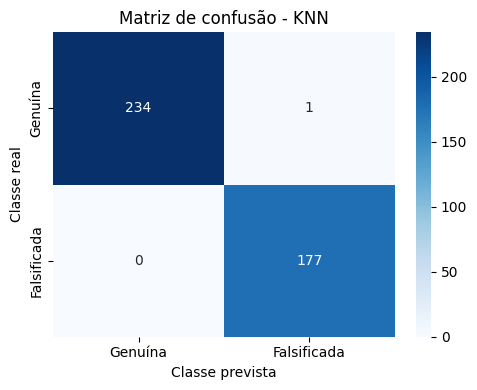

MODELO: Árvore de Decisão
                 precision    recall  f1-score   support

    Genuína (0)       1.00      0.98      0.99       235
Falsificada (1)       0.98      0.99      0.99       177

       accuracy                           0.99       412
      macro avg       0.99      0.99      0.99       412
   weighted avg       0.99      0.99      0.99       412



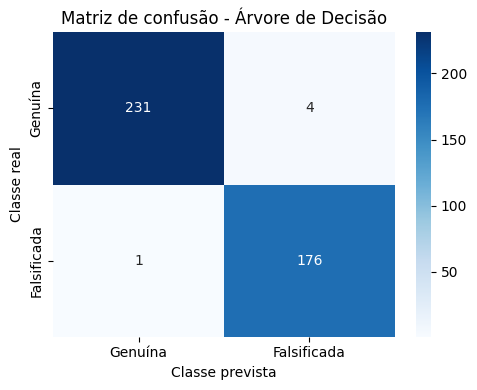

MODELO: Random Forest
                 precision    recall  f1-score   support

    Genuína (0)       1.00      0.99      1.00       235
Falsificada (1)       0.99      1.00      0.99       177

       accuracy                           1.00       412
      macro avg       0.99      1.00      1.00       412
   weighted avg       1.00      1.00      1.00       412



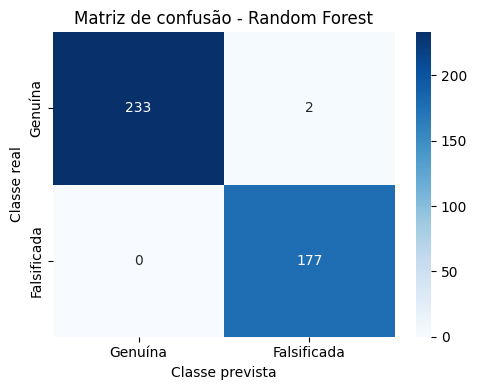

MODELO: SVM
                 precision    recall  f1-score   support

    Genuína (0)       1.00      1.00      1.00       235
Falsificada (1)       1.00      1.00      1.00       177

       accuracy                           1.00       412
      macro avg       1.00      1.00      1.00       412
   weighted avg       1.00      1.00      1.00       412



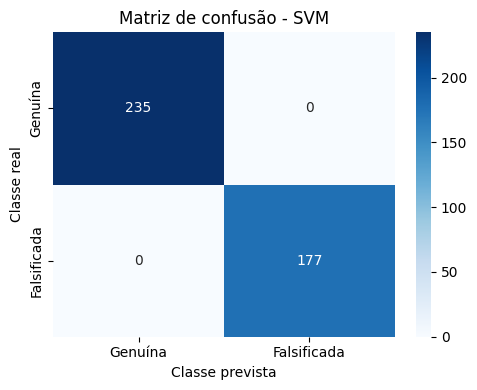

MODELO: MLP
                 precision    recall  f1-score   support

    Genuína (0)       1.00      1.00      1.00       235
Falsificada (1)       1.00      1.00      1.00       177

       accuracy                           1.00       412
      macro avg       1.00      1.00      1.00       412
   weighted avg       1.00      1.00      1.00       412



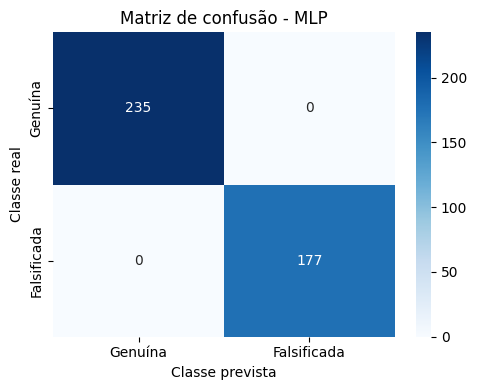

In [16]:

for nome, y_pred in previsoes.items():
    print("=" * 60)
    print(f"MODELO: {nome}")
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Genuína (0)", "Falsificada (1)"],
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Genuína", "Falsificada"],
        yticklabels=["Genuína", "Falsificada"]
    )

    plt.title(f"Matriz de confusão - {nome}")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.tight_layout()
    plt.show()
